In [3]:
import os
import h5py
import requests
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive,userdata
drive.mount("/content/drive")

Mounted at /content/drive


In [6]:
baseUrl = 'http://www.tng-project.org/api/'
headers = {"api-key":userdata.get("TNG_API_KEY")}

In [7]:
def get(path, params=None):
    # make HTTP GET request to path
    r = requests.get(path, params=params, headers=headers)

    # raise exception if response code is not HTTP SUCCESS (200)
    r.raise_for_status()

    if r.headers['content-type'] == 'application/json':
        return r.json() # parse json responses automatically

    if 'content-disposition' in r.headers:
        filename = r.headers['content-disposition'].split("filename=")[1]
        with open(filename, 'wb') as f:
            f.write(r.content)
        return filename # return the filename string

    return r

In [8]:
r = get(baseUrl)

In [12]:
os.chdir("/content/drive/MyDrive/TNGdata")

In [14]:
data = np.load("subhalo_data_with_bhmasses.npz")
data = data["data"]

sfrs = data[:,0,0]
bhmdots = data[:,0,1]
mass_stars = data[:,0,2]
mass_bhmdots = data[:,0,3]

mean_b_fields = data[:,0,-2]
median_b_fields = data[:,0,-1]

normalized_sfrs = sfrs / mass_stars
normalized_bhmdots = bhmdots / mass_bhmdots

/tmp/ipykernel_1019/3254282534.py:13: RuntimeWarning: invalid value encountered in divide
  normalized_bhmdots = bhmdots / mass_bhmdots


In [25]:
valid_b_mask = (mean_b_fields > 0)
clean_mean_b = mean_b_fields[valid_b_mask]

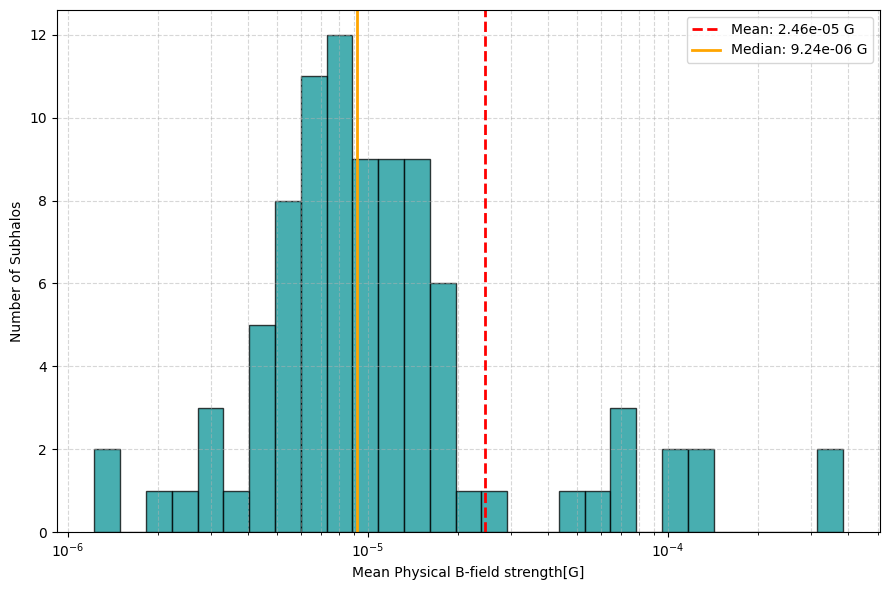

In [26]:
plt.figure(figsize=(9, 6))
bins = np.logspace(np.log10(clean_mean_b.min()), np.log10(clean_mean_b.max()), 30)

plt.hist(clean_mean_b, bins=bins, color='#0a9396', alpha=0.75, edgecolor='black')

mean_val = np.mean(clean_mean_b)
median_val = np.median(clean_mean_b)
plt.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2e} G')
plt.axvline(median_val, color='orange', linestyle='-', linewidth=2, label=f'Median: {median_val:.2e} G')

plt.xscale('log')
plt.xlabel('Mean Physical B-field strength[G]')
plt.ylabel('Number of Subhalos')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.savefig("mean_B_fields_histogram.png", dpi=300)
plt.show()

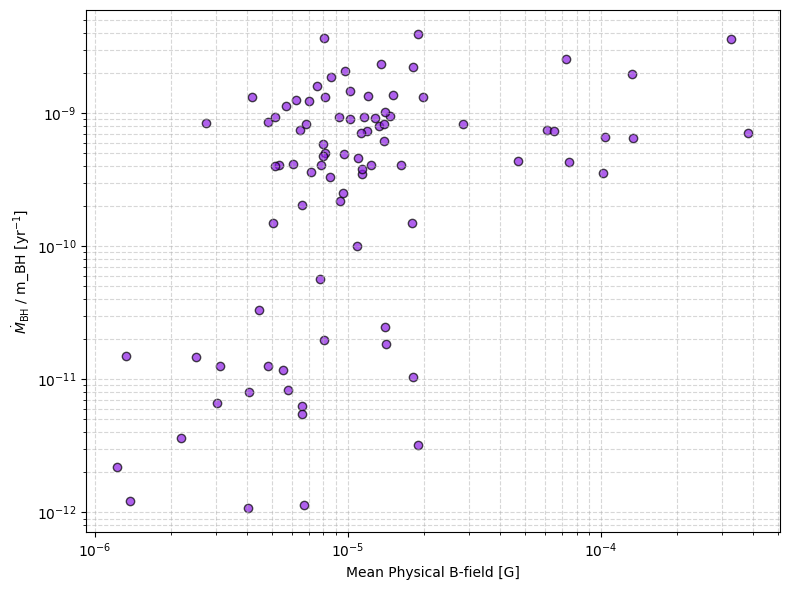

In [30]:
valid_scatter_mask = (mean_b_fields > 0) & (sfrs >= 0) & (bhmdots >= 0) & (mass_stars > 0) & (mass_bhmdots > 0)

clean_b = mean_b_fields[valid_scatter_mask]
clean_norm_bhmdot = normalized_bhmdots[valid_scatter_mask]

plt.figure(figsize=(8, 6))
plt.scatter(clean_b, clean_norm_bhmdot, color='#8e1ce6', alpha=0.7, edgecolors='black')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Mean Physical B-field [G]')
plt.ylabel(r'$\dot{M}_{\text{BH}}$ / m_BH [$\text{yr}^{-1}$]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("norm_bhmdot_vs_bfield.png", dpi=300)
plt.show()

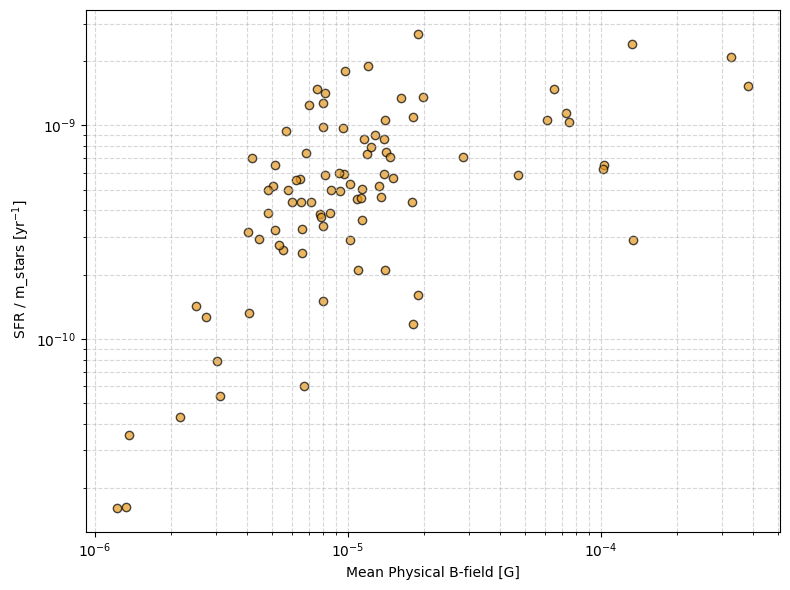

In [31]:
clean_norm_sfr = normalized_sfrs[valid_scatter_mask]

plt.figure(figsize=(8, 6))
plt.scatter(clean_b, clean_norm_sfr, color='#e6981c', alpha=0.7, edgecolors='black')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Mean Physical B-field [G]')
plt.ylabel(r' $\text{SFR}$ / m_stars [$\text{yr}^{-1}$]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("norm_sfr_vs_b_field.png", dpi=300)
plt.show()

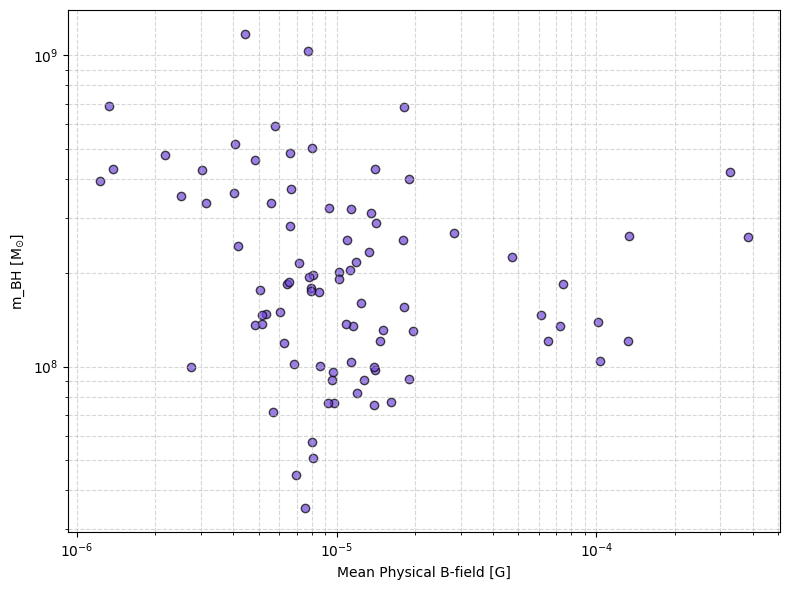

In [32]:
clean_mbh = mass_bhmdots[valid_scatter_mask]

plt.figure(figsize=(8, 6))
plt.scatter(clean_b, clean_mbh, color='#7148d9', alpha=0.7, edgecolors='black')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Mean Physical B-field [G]')
plt.ylabel('m_BH [$\\mathrm{M}_{\\odot}$]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("mbh_vs_bfield.png", dpi=300)
plt.show()

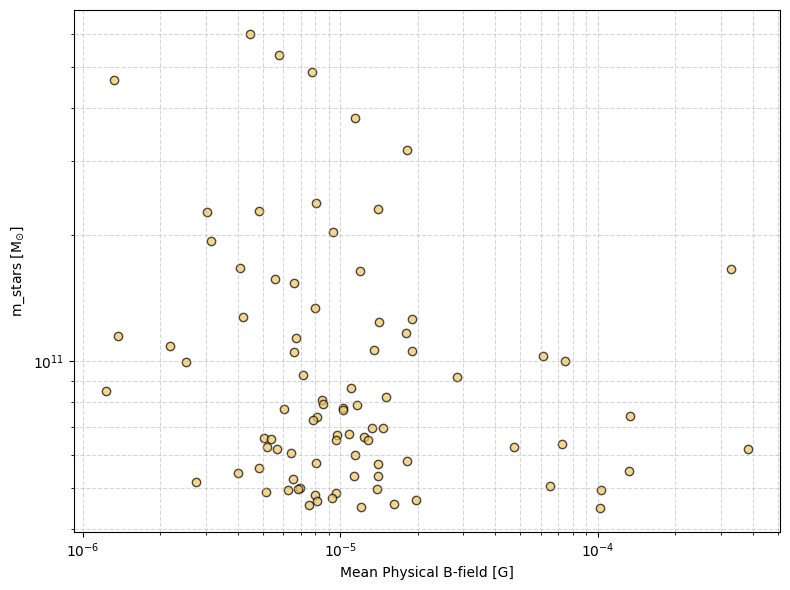

In [33]:
clean_mstar = mass_stars[valid_scatter_mask]

plt.figure(figsize=(8, 6))
plt.scatter(clean_b, clean_mstar, color='#f0c65d', alpha=0.7, edgecolors='black')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Mean Physical B-field [G]')
plt.ylabel('m_stars [$\\mathrm{M}_{\\odot}$]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("mstar_vs_bfield.png", dpi=300)
plt.show()